

Устинова Алиса

**Набор данных:** Amazon Books, `fetch_amazon_books(subset="leave-one-out")` из `skrecsys`.  
**Что рекомендую:** книги, с которыми пользователь ещё не взаимодействовал

**Что считается релевантным:** положительное событие (оценка 4–5, если это явные оценки; 1 для бинарных событий; любое наблюдаемое взаимодействие, если оценок нет)


## 0. Установка библиотек и настройки

In [2]:
%pip install  skrecsys numpy pandas scipy matplotlib


In [3]:
import ast
import csv
import gzip
import json
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.linalg import cho_factor, cho_solve
from IPython.display import display

SEED = 42
K = 10
MAX_ITEMS = 1800
MAX_USERS = 30000
MAX_EVENTS = 230000
EVAL_USERS = 1500
METADATA_PATH = None
np.random.seed(SEED)
print('Настройки готовы. seed =', SEED)


Настройки готовы. seed = 42


## 1. Загрузка и описание данных

Используем ровно выбранный источник: `fetch_amazon_books(subset="leave-one-out")`. Пакет может возвращать объект с отдельными частями train/test — мы извлекаем наблюдаемые взаимодействия, а затем применяем единое разбиение для всех моделей.

**Первичный источник семейства Amazon Product Data:** https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/ . Точную версию и происхождение данных, которые поставляет конкретная версия `skrecsys`, нужно проверить по документации пакета: эта ссылка не гарантирует идентичность версий.

Поля после приведения к общей таблице: `user_id` — идентификатор пользователя; `item_id` — идентификатор книги; `rating` — оценка или положительный сигнал; `timestamp` — время события, **если оно есть в исходных данных**; `source_part` — часть исходного объекта.

### Вспомогательные функции (запустить один раз)

In [4]:
# Общие функции для работы с матрицами и top-10

def positive_csr(matrix: sparse.spmatrix) -> sparse.csr_matrix:
    mat = matrix.tocsr().astype(np.float64).copy()
    mat.sum_duplicates()
    if mat.nnz:
        mat.data[:] = 1.
    mat.eliminate_zeros()
    return mat


def require_matrix(matrix: sparse.spmatrix) -> sparse.csr_matrix:
    out = positive_csr(matrix)
    if out.shape[0] == 0 or out.shape[1] < 2 or out.nnz == 0:
        raise ValueError('Для обучения нужны >=1 пользователь, >=2 объекта и ненулевая матрица')
    return out


def topk(scores: np.ndarray, known: sparse.csr_matrix, users, k=10) -> np.ndarray:
    """Точное ранжирование по полному каталогу, сначала больший score, затем меньший ID."""
    scores = np.asarray(scores, dtype=np.float64).copy()
    users = np.asarray(users, dtype=int)
    if scores.shape != (len(users), known.shape[1]):
        raise ValueError('Ожидалась матрица score размера (число пользователей, число объектов).')
    scores[~np.isfinite(scores)] = -np.inf
    out = np.full((len(users), k), -1, dtype=np.int32)
    item_ids = np.arange(scores.shape[1])
    for row, u in enumerate(users):
        seen = known.indices[known.indptr[u]:known.indptr[u+1]]
        scores[row, seen] = -np.inf
        order = np.lexsort((item_ids, -scores[row]))
        order = order[np.isfinite(scores[row, order])]
        out[row, :min(k, len(order))] = order[:k]
    return out


In [5]:
# Загрузка, очистка, разбиение и обработка метаданных

ID_USER = ['user_id','user_ids','users','user','userid','reviewerid','reviewer_id','uid','user_idx','user_index']
ID_ITEM = ['item_id','item_ids','items','item','itemid','asin','parent_asin','product_id','iid','item_idx','book_id']
RATINGS = ['rating','ratings','overall','score','scores','stars','review_score']
TIMES = ['timestamp','unixreviewtime','unix_review_time','time','review_time','date','unix_time']


def _col(df, names):
    norm = {str(k).lower().replace(' ', '_').replace('-', '_'): k for k in df.columns}
    return next((norm[k] for k in names if k in norm), None)


def _events_frame(obj):
    """Пытаемся прочесть один объект как события, иначе None (без выдуманных полей)."""
    if obj is None: return None
    if sparse.issparse(obj):
        m = obj.tocoo()
        return pd.DataFrame({'user_id': m.row, 'item_id': m.col, 'rating': m.data})
    if isinstance(obj, pd.DataFrame): return obj.copy()
    if hasattr(obj, 'to_pandas'):
        try: return _events_frame(obj.to_pandas())
        except (ValueError, TypeError, AttributeError): pass
    if isinstance(obj, np.ndarray) and obj.ndim == 2 and obj.shape[1] in (2, 3, 4):
        names = ['user_id', 'item_id', 'rating', 'timestamp'][:obj.shape[1]]
        return pd.DataFrame(obj, columns=names)
    if isinstance(obj, dict):
        if _col(pd.DataFrame(columns=list(obj.keys())), ID_USER) is not None and _col(pd.DataFrame(columns=list(obj.keys())), ID_ITEM) is not None:
            try: return pd.DataFrame(obj)
            except (ValueError, TypeError): return None
    if isinstance(obj, (tuple,list)) and len(obj)>=2 and not any(isinstance(x,(dict,pd.DataFrame)) or sparse.issparse(x) for x in obj):
        # Например, (user_ids, item_ids, ratings) одной таблицы.
        try:
            if all(hasattr(x, '__len__') for x in obj) and len(set(map(len,obj)))==1:
                return pd.DataFrame({k: x for k, x in zip(['user_id','item_id','rating','timestamp'],obj)})
        except (ValueError, TypeError): pass
    return None


def _extract(obj, path='books', depth=0):
    if depth>4: return []
    frame = _events_frame(obj)
    if frame is not None:
        if _col(frame, ID_USER) is not None and _col(frame, ID_ITEM) is not None:
            return [(path, frame)]
        return []
    parts = []
    if isinstance(obj, dict):
        for key in ('interactions','ratings','events','data','train','validation','valid','val','test',
                    'df','interactions_df','ratings_df','train_df','val_df','test_df','train_data','val_data','test_data','train_matrix','validation_matrix','test_matrix',
                    'train_interactions','test_interactions'):
            if key in obj: parts.extend(_extract(obj[key],path+'.'+key,depth+1))
    elif isinstance(obj,(tuple,list)):
        for j, p in enumerate(obj): parts.extend(_extract(p,path+f'[{j}]',depth+1))
    else:
        for key in ('interactions','ratings','events','data','train','validation','valid','val','test',
                    'df','interactions_df','ratings_df','train_df','val_df','test_df','train_data','val_data','test_data','train_matrix','test_matrix',
                    'train_interactions','test_interactions'):
            try: p = getattr(obj,key,None)
            except Exception: p = None
            if p is not None and p is not obj: parts.extend(_extract(p,path+'.'+key,depth+1))
    return parts


def _normalize_frame(frame, source):
    uc, ic = _col(frame, ID_USER), _col(frame, ID_ITEM)
    if uc is None or ic is None:
        raise ValueError(f'В части {source} нет колонок ID; есть {list(frame.columns)}')
    out = pd.DataFrame({'user_id': frame[uc].astype('string').str.strip(),
                        'item_id': frame[ic].astype('string').str.strip()})
    rc, tc = _col(frame, RATINGS), _col(frame, TIMES)
    if rc is not None: out['rating'] = pd.to_numeric(frame[rc], errors='coerce')
    if tc is not None:
        raw = frame[tc]
        # Число или строка-число => Unix timestamps (секунды либо миллисекунды).
        number = pd.to_numeric(raw, errors='coerce')
        if (not pd.api.types.is_datetime64_any_dtype(raw)) and number.notna().mean()>.98:
            number = number.astype(float)
            med = float(number.dropna().abs().median()) if number.notna().any() else 0.
            if med>1e14: number /= 1e6  # микросекунды
            elif med>1e11: number /= 1e3  # миллисекунды
            out['timestamp'] = number
        else:
            parsed = pd.to_datetime(raw, errors='coerce', utc=True)
            out['timestamp'] = np.where(parsed.notna(),parsed.astype('int64') / 1e9, np.nan)
    out['source_part'] = source
    return out


def fetch_amazon_books_events():
    """Выбранный пользователем источник. Пакет качает данные при первом запуске."""
    from skrecsys.datasets import fetch_amazon_books
    books = fetch_amazon_books(subset='leave-one-out')
    print('Тип объекта skrecsys:',type(books))
    if isinstance(books,dict): print('Ключи:',list(books))
    else: print('Атрибуты:',[k for k in dir(books) if not k.startswith('_')][:35])
    parts = _extract(books)
    if not parts:
        raise TypeError('Не удалось извлечь user/item события. Нужен адаптер к версии skrecsys. '
                        'Пришлите type(books), books.keys()/dir(books) и пример элемента без персональных данных.')
    for label, part in parts:
        print('Часть:', label, '| размер:',part.shape,'| поля:',list(part.columns)[:15])
    data = pd.concat([_normalize_frame(f, p) for p,f in parts], ignore_index=True)
    for col in ('rating','timestamp'):
        if col not in data: data[col] = np.nan
    return data, books


def raw_report(raw):
    return {'n_raw_events': len(raw), 'raw_users': raw.user_id.nunique(),
            'raw_items': raw.item_id.nunique(),
            'missing_user': int(raw.user_id.isna().sum()),
            'missing_item': int(raw.item_id.isna().sum()),
            'missing_rating': int(raw.rating.isna().sum()),
            'missing_timestamp': int(raw.timestamp.isna().sum()),
            'exact_duplicate_events': int(raw.duplicated(['user_id','item_id','rating','timestamp']).sum()),
            'repeated_user_item_pairs': int(raw.duplicated(['user_id','item_id']).sum())}


def sanitize_events(raw, positive_rating_threshold=4.0):
    """Выбор положительных событий и агрегация user-item в один implicit positive."""
    d = raw.copy()
    d['user_id'] = d.user_id.astype('string')
    d['item_id'] = d.item_id.astype('string')
    d = d.dropna(subset=['user_id','item_id'])
    d = d[(d.user_id.str.len()>0) & (d.item_id.str.len()>0)]
    vals = d.rating.dropna()
    if vals.empty:
        rule = 'Нет оценок: все наблюдаемые события считаются положительными (implicit feedback).'
    elif vals.min() >= 0 and vals.max() <= 1:
        d = d[d.rating == 1]
        rule = 'Бинарная обратная связь: сохраняем rating=1.'
    else:
        d = d[d.rating >= positive_rating_threshold]
        rule = f'Явные оценки: релевантность = rating >= {positive_rating_threshold:g}.'
    # Сохраняем последнее известное событие пары; при timestamp это строго последний отзыв.
    d = d.sort_values(['timestamp','user_id','item_id'],kind='mergesort',na_position='first')
    d = d.drop_duplicates(['user_id','item_id'],keep='last').reset_index(drop=True)
    print('Определение положительного события:', rule)
    return d, rule


def _core_filter(d, min_user, min_item):
    d = d.copy()
    for _ in range(40):
        old = len(d)
        users = d.groupby('user_id', observed=True).size()
        items = d.groupby('item_id', observed=True).size()
        d = d[d.user_id.isin(users.index[users>=min_user]) &
              d.item_id.isin(items.index[items>=min_item])]
        if len(d)==old: break
    return d.copy()


def choose_subset(data, top_items=1800, top_users=30000, max_events=230000,
                  min_user=5, min_item=8, seed=42, strict=True):
    """Временные данные: ID для подвыборки выбираем только по раннему train-окну.

    При отсутствии полного timestamp: фиксированная offline-подвыборка до random LOO.
    Все параметры выбора задаются ДО расчёта validation/test метрик.
    """
    if len(data)==0: raise ValueError('После выделения положительных событий выборка пуста.')
    temporal_complete = ('timestamp' in data and data.timestamp.notna().all()
                         and data.timestamp.nunique()>=3)
    stats_extra = {'temporal_selection_train_only':bool(temporal_complete)}
    if temporal_complete:
        cut1,cut2 = map(float,np.quantile(data.timestamp.to_numpy(dtype=float),[.8,.9]))
        if cut1>=cut2: raise ValueError('Недостаточно разрешения timestamps для временных порогов.')
        reference = data[data.timestamp < cut1].copy()
        stats_extra['selection_cutoffs']={'train_end':cut1,'validation_end':cut2}
        print('Параметры подвыборки оцениваются по историческому окну timestamp <',cut1)
    else:
        reference = data.copy()
        stats_extra['selection_cutoffs'] = None
        print('timestamps отсутствуют/неполны: offline-подвыборка формируется до random LOO.')

    counts_i = reference.groupby('item_id').size().sort_values(ascending=False,kind='stable')
    ids_i = set(counts_i.head(top_items).index)
    reference = reference[reference.item_id.isin(ids_i)]
    counts_u = reference.groupby('user_id').size().sort_values(ascending=False,kind='stable')
    ids_u = set(counts_u.head(top_users).index)
    reference = reference[reference.user_id.isin(ids_u)]
    reference = _core_filter(reference,min_user,min_item)

    # Все будущие события отобранных только по train ID попадают в одноименную выборку,
    # но выбор ID и статистика активности не зависели от validation/test.
    d = data[data.user_id.isin(reference.user_id.unique()) &
             data.item_id.isin(reference.item_id.unique())].copy()
    if len(d)>max_events:
        uc = reference.groupby('user_id').size()
        keys = uc.index.to_numpy().copy()
        rng = np.random.default_rng(seed)
        rng.shuffle(keys)
        # Для временного режима лимитируем объём ИСТОРИЧЕСКОГО фрагмента (~80%).
        budget = max_events*.80 if temporal_complete else max_events
        chosen,total=[],0
        for u in keys:
            c=int(uc.loc[u])
            if total+c <= budget:
                chosen.append(u);total+=c
            if total>=.99*budget:break
        reference=reference[reference.user_id.isin(chosen)]
        reference=_core_filter(reference,min_user,min_item)
        d = data[data.user_id.isin(reference.user_id.unique()) &
                 data.item_id.isin(reference.item_id.unique())].copy()
        if not temporal_complete and len(d)>max_events:
            # Без времён никакого усечения отдельных событий: ошибка честнее.
            raise ValueError('Не удалось уложить целые истории пользователей в max_events.')
    d=d.sort_values(['user_id','timestamp','item_id'],kind='mergesort').reset_index(drop=True)
    stats = {'n_events':len(d),'n_users':d.user_id.nunique(),'n_items':d.item_id.nunique(),
             'density': float(len(d)/(max(1,d.user_id.nunique()*d.item_id.nunique()))),**stats_extra}
    print('После очистки и воспроизводимого отбора:',stats)
    if strict and not(100000 <= stats['n_events'] <= 2000000 and
                      stats['n_users'] >= 1000 and stats['n_items'] >= 1000):
        raise ValueError('Выборка НЕ соответствует лимитам (>=100000 событий, >=1000 пользователей '
                         'и >=1000 книг). Увеличьте top_items/top_users/max_events или ослабьте core '
                         'и заново запустите весь протокол ДО подбора моделей. '
                         f'Текущие значения: {stats}')
    return d, stats


def split_interactions(d, seed=42, train_ratio=.8, val_ratio=.1, temporal_cutoffs=None):
    """При *полных* timestamp — строго глобальная хронология 80/10/10.
    Иначе seeded user-wise leave-two-out: разные события val и test для каждого пользователя.
    """
    z = d.copy()
    time_available = ('timestamp' in z and z.timestamp.notna().all() and
                      z.timestamp.nunique()>=3)
    if time_available:
        z = z.sort_values(['timestamp','user_id','item_id'],kind='mergesort')
        # Порог по значениям, а не позиции, чтобы одинаковое timestamp не попало в обе части.
        cut1, cut2 = (temporal_cutoffs if temporal_cutoffs is not None else
                      np.quantile(z.timestamp.to_numpy(dtype=float),[train_ratio,train_ratio+val_ratio]))
        train = z[z.timestamp < cut1].copy()
        val = z[(z.timestamp >= cut1)&(z.timestamp < cut2)].copy()
        test = z[z.timestamp>=cut2].copy()
        if min(len(train),len(val),len(test))<1:
            raise ValueError('Временные границы создали пустую часть. Проверьте точность timestamp.')
        method = f'GLOBAL_TEMPORAL train<t1, t1<=val<t2, test>=t2; t1={cut1}, t2={cut2}'
        assert train.timestamp.max()<val.timestamp.min()<test.timestamp.min()
    else:
        if temporal_cutoffs is not None:
            raise ValueError('Временные пороги указаны, но timestamps не полны.')
        # Не выдаём искусственный порядок за реальную хронологию.
        rng = np.random.default_rng(seed)
        z = z.sort_values(['user_id','item_id'],kind='mergesort')
        z['_order'] = rng.random(len(z))
        z = z.sort_values(['user_id','_order'],kind='mergesort')
        rev = z.groupby('user_id',sort=False).cumcount(ascending=False)
        train = z[rev>=2].copy();val = z[rev==1].copy();test = z[rev==0].copy()
        method = f'RANDOM_USER_LOO seed={seed} (timestamps нет/частично отсутствуют)'
    for x in (train,val,test):
        x.drop(columns=['_order'],inplace=True,errors='ignore')
    keys = [set(zip(x.user_id,x.item_id)) for x in (train,val,test)]
    assert not (keys[0] & keys[1] or keys[0] & keys[2] or keys[1] & keys[2])
    print('Разбиение:',method,'| событий:',(len(train),len(val),len(test)))
    return train, val, test, method


@dataclass
class Encoded:
    history: sparse.csr_matrix
    truth: sparse.csr_matrix
    users: pd.Index
    items: pd.Index
    stats: dict
    item_categories: list | None = None
    metadata_info: dict | None = None

    def example_ids(self, user, item_ids):
        return str(self.users[int(user)]), [str(self.items[int(i)]) for i in item_ids]


def encode_for_evaluation(train, holdout):
    """Training vocabulary only; cold users/items cannot be scored by these 5 models.
    Cold counts explicitly reported, never counted as negatives.
    """
    users = pd.Index(sorted(train.user_id.unique()))
    items = pd.Index(sorted(train.item_id.unique()))
    um = pd.Series(np.arange(len(users)),index=users)
    im = pd.Series(np.arange(len(items)),index=items)
    trainu = train.user_id.map(um).astype(np.int32).to_numpy()
    traini = train.item_id.map(im).astype(np.int32).to_numpy()
    X = sparse.csr_matrix((np.ones(len(train),dtype=np.float32),(trainu,traini)),
                          shape=(len(users),len(items)))
    X = positive_csr(X)
    valid = holdout.user_id.isin(um.index) & holdout.item_id.isin(im.index)
    hd = holdout[valid]
    hu = hd.user_id.map(um).astype(np.int32).to_numpy()
    hi = hd.item_id.map(im).astype(np.int32).to_numpy()
    Y = sparse.csr_matrix((np.ones(len(hd),dtype=np.float32),(hu,hi)),shape=X.shape)
    Y = positive_csr(Y)
    conflict = X.multiply(Y).nnz
    if conflict:
        raise ValueError(f'Пересечение train и holdout по {conflict} парам — это утечка')
    usable = np.flatnonzero((np.diff(X.indptr)>0)&(np.diff(Y.indptr)>0)&
                            ((len(items)-np.diff(X.indptr))>=10))
    stats = {'train_users':len(users),'train_items':len(items),'train_events':int(X.nnz),
             'holdout_events_before_cold_filter':len(holdout),
             'holdout_events_in_vocabulary':int(Y.nnz),
             'discarded_cold_events':int(len(holdout)-valid.sum()),
             'holdout_users_evaluable_at_10':int(len(usable)),
             'holdout_event_coverage':float(Y.nnz/max(len(holdout),1))}
    if len(usable)==0: raise ValueError('Нет подходящих пользователей с историями и held-out целями.')
    return Encoded(X,Y,users,items,stats)


def _flatten_categories(value):
    if value is None: return []
    if isinstance(value,str):
        v = value.strip()
        if not v: return []
        if v.startswith('['):
            try: return _flatten_categories(json.loads(v.replace("'",'"')))
            except (ValueError,TypeError): pass
        return [v]
    if isinstance(value,(list,tuple,set)):
        ret=[]
        for x in value: ret.extend(_flatten_categories(x))
        return list(dict.fromkeys(ret))[:8]
    return [str(value)]


def read_optional_categories(path, item_ids):
    """Читаем CSV/JSONL(+gzip) потоково, не загружаем весь Amazon metadata в RAM.
    Совпадение по ID обязательно. Не придумываем категории при отсутствии метафайла.
    """
    item_ids = [str(i) for i in item_ids]
    if not path:
        print('Сторонние категории отсутствуют; FM использует реальные train-derived метапризнаки '
              '(бакет активности пользователя и популярности книги).')
        return [[] for _ in item_ids], {'metadata_path':None,'category_coverage':0.}
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'Указан METADATA_PATH, но файл не найден: {path}')
    opener = gzip.open if path.suffix=='.gz' else open
    id_to_cats = {}
    item_set = set(item_ids)
    is_jsonl = '.jsonl' in path.name or '.json' in path.name
    with opener(path,'rt',encoding='utf-8',errors='replace') as fh:
        if is_jsonl:
            def iter_records(lines):
                for line in lines:
                    if not line.strip(): continue
                    try: yield json.loads(line)
                    except json.JSONDecodeError:
                        # В старых Amazon Reviews 2018 встречается Python-dict-per-line.
                        try: yield ast.literal_eval(line)
                        except (ValueError, SyntaxError): continue
            records = iter_records(fh)
        else:
            records = csv.DictReader(fh)
        for rec in records:
            k = next((str(rec[field]) for field in ID_ITEM if field in rec and rec[field] is not None
                      and str(rec[field]) in item_set),None)
            if k is None: continue
            cats = next((rec[field] for field in ('categories','category','genres','genre','main_cat')
                         if field in rec and rec[field] not in (None,'')),None)
            id_to_cats[k] = _flatten_categories(cats)
            if len(id_to_cats)==len(item_set):break
    result = [id_to_cats.get(i,[]) for i in item_ids]
    covered = sum(bool(row) for row in result)
    meta_stats={'metadata_path':str(path),'category_coverage':covered/len(item_ids),
                'items_with_categories':covered,'items_total':len(item_ids)}
    print('Покрытие категориями исходного метафайла:',meta_stats)
    if covered==0:
        print('ВНИМАНИЕ: ни одного совпадения item_id/ASIN. Проверьте версию Amazon Books! '
              'Категории не будут использованы; train-derived признаки FM останутся.')
    return result,meta_stats


In [6]:
raw, books = fetch_amazon_books_events()
print('Исходные данные, первые строки:')
display(raw.head())
print('Статистика до очистки:')
display(pd.DataFrame([raw_report(raw)]).T.rename(columns={0:'значение'}))
print('Поля:', list(raw.columns))
print('user_id — пользователь; item_id — книга; rating — оценка (если есть); '
      'timestamp — время события (если есть).')

Тип объекта skrecsys: <class 'sklearn.utils._bunch.Bunch'>
Ключи: ['feature_names', 'target_names', 'DESCR', 'data', 'target', 'timestamps', 'user_info', 'item_info', 'train_indices', 'test_indices']
Часть: books.data | размер: (8069177, 2) | поля: ['user_id', 'item_id']
Исходные данные, первые строки:


,user_id,item_id,source_part,rating,timestamp
0,0,79485,books.data,NaN,NaN
1,0,234852,books.data,NaN,NaN
2,0,389526,books.data,NaN,NaN
3,0,403592,books.data,NaN,NaN
4,0,405328,books.data,NaN,NaN


Статистика до очистки:


,значение
n_raw_events,8069177
raw_users,694897
raw_items,674079
missing_user,0
missing_item,0
missing_rating,8069177
missing_timestamp,8069177
exact_duplicate_events,0
repeated_user_item_pairs,0


Поля: ['user_id', 'item_id', 'source_part', 'rating', 'timestamp']
user_id — пользователь; item_id — книга; rating — оценка (если есть); timestamp — время события (если есть).


## 2. EDA и подготовка

1. Удаляем записи без ID и повторные пары «пользователь — книга».
2. Для явных оценок оставляем оценки 4–5; для бинарных — положительные.
3. Ограничиваем каталог по популярности книг, а пользователей — по активности. Для исторического разбиения отбор ID проводится **только по раннему периоду**, чтобы будущее не влияло на признаки.
4. Проверяем требования: **100 000–2 000 000 событий, не менее 1000 пользователей и 1000 книг**.
5. Показываем распределения активности и популярности, плотность матрицы и информацию о пропусках/дубликатах.

In [7]:
positive, relevance_rule = sanitize_events(raw, positive_rating_threshold=4)
clean, stats = choose_subset(
    positive, top_items=MAX_ITEMS, top_users=MAX_USERS,
    max_events=MAX_EVENTS, min_user=5, min_item=8, seed=SEED, strict=True
)
print('Правило релевантности:', relevance_rule)
print('После очистки:')
display(pd.DataFrame([stats]).T.rename(columns={0:'значение'}))
print('Удалено записей (исходные минус отобранные):', len(raw)-len(clean))
print('Разреженность:', round(1-stats['density'], 5))

Определение положительного события: Нет оценок: все наблюдаемые события считаются положительными (implicit feedback).
timestamps отсутствуют/неполны: offline-подвыборка формируется до random LOO.
После очистки и воспроизводимого отбора: {'n_events': 227699, 'n_users': 23568, 'n_items': 1795, 'density': 0.005382374855098363, 'temporal_selection_train_only': False, 'selection_cutoffs': None}
Правило релевантности: Нет оценок: все наблюдаемые события считаются положительными (implicit feedback).
После очистки:


,значение
n_events,227699
n_users,23568
n_items,1795
density,0.005382
temporal_selection_train_only,False
selection_cutoffs,None


Удалено записей (исходные минус отобранные): 7841478
Разреженность: 0.99462


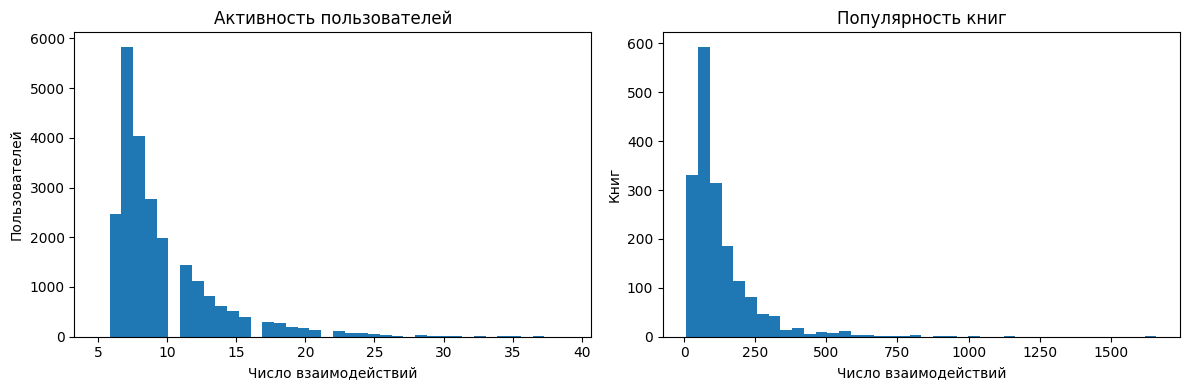

Активность: медиана 8.0 | максимум 39
Популярность: медиана 88.0 | максимум 1661


In [8]:
# Два основных графика EDA: пользователи и книги.
activity = clean.groupby('user_id').size()
popularity = clean.groupby('item_id').size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(activity, bins=40)
axes[0].set(title='Активность пользователей', xlabel='Число взаимодействий', ylabel='Пользователей')
axes[1].hist(popularity, bins=40)
axes[1].set(title='Популярность книг', xlabel='Число взаимодействий', ylabel='Книг')
plt.tight_layout(); plt.show()
print('Активность: медиана', activity.median(), '| максимум', activity.max())
print('Популярность: медиана', popularity.median(), '| максимум', popularity.max())
if raw['rating'].notna().any():
    raw['rating'].value_counts().sort_index().plot.bar(title='Исходные оценки', figsize=(6,3))
    plt.xlabel('Оценка'); plt.ylabel('Число событий'); plt.show()

In [9]:

categories, category_info = read_optional_categories(METADATA_PATH, sorted(clean.item_id.unique()))


Сторонние категории отсутствуют; FM использует реальные train-derived метапризнаки (бакет активности пользователя и популярности книги).
Покрытие книг внешними категориями: 0.0
Для FM будут использованы только признаки, полученные из train, и (если указаны) категории книг.


## 3. Единый протокол оценки

- **При наличии полных timestamps:** глобальное временное разбиение на ранний train, следующий validation и самый поздний test.
- **Если времени нет или оно неполно:** фиксированное случайное разбиение по пользователям (одно событие на validation, одно на test). Такое разбиение **не является временным**.
- **Кандидаты:** весь каталог, доступный в train, за исключением книг, уже известных пользователю.
- **Cold start:** взаимодействия с совершенно новыми пользователями/книгами не могут быть оценены этими моделями; количество исключений выводим отдельно.
- **Метрики:** `NDCG@10` и `Recall@10` (дополнительно HitRate и MRR). Во всех случаях один критерий релевантности и одни тестовые пользователи.

Разные модели могут обучаться на разных целевых значениях, но **цели test для всех одинаковы**.

In [10]:
cut = stats.get('selection_cutoffs')
cutoffs = (cut['train_end'], cut['validation_end']) if cut else None
train, val, test, method = split_interactions(clean, seed=SEED, temporal_cutoffs=cutoffs)
val_data = encode_for_evaluation(train, val)
print('Протокол:', method)
print('Размеры частей:', {'train':len(train), 'validation':len(val), 'test':len(test)})
print('Validation / cold start:', val_data.stats)

def evaluation_users(data, limit=EVAL_USERS):
    user_has_history = np.diff(data.history.indptr) > 0
    user_has_truth = np.diff(data.truth.indptr) > 0
    n_candidates = data.history.shape[1]-np.diff(data.history.indptr)
    ids = np.flatnonzero(user_has_history & user_has_truth & (n_candidates >= K))
    rng = np.random.default_rng(SEED)
    if len(ids) > limit:
        ids = np.sort(rng.choice(ids, size=limit, replace=False))
    return ids

val_users = evaluation_users(val_data)
print('Оценка на validation: ', len(val_users), 'пользователей.')

Разбиение: RANDOM_USER_LOO seed=42 (timestamps нет/частично отсутствуют) | событий: (180563, 23568, 23568)
Протокол: RANDOM_USER_LOO seed=42 (timestamps нет/частично отсутствуют)
Размеры частей: {'train': 180563, 'validation': 23568, 'test': 23568}
Validation / cold start: {'train_users': 23568, 'train_items': 1795, 'train_events': 180563, 'holdout_events_before_cold_filter': 23568, 'holdout_events_in_vocabulary': 23568, 'discarded_cold_events': 0, 'holdout_users_evaluable_at_10': 23568, 'holdout_event_coverage': 1.0}
Оценка на validation:  1500 пользователей.


## 4.

| Модель | Как работает |
|:--|:--|
| **1. ItemKNN** | Похожие книги по косинусному сходству; скор — сумма сходств с уже известными книгами. |
| **2. Implicit ALS** | Факторизация матрицы предпочтений: $\hat r_{ui}=x_u^\top y_i$; наблюдаемая цель $p_{ui}=1$, ненаблюдаемая $p_{ui}=0$. |
| **3. EASE** | Линейная модель: $\min_B \|A-AB\|_F^2+\lambda\|B\|_F^2$, диагональ $B$ равна нулю. |
| **4. FM + BPR** | Факторизационная машина с ID и метапризнаками из **только train** (группы активности пользователей и популярности книг). Если есть внешний файл категорий — используем и категории. |
| **5. Novelty-ALS** | Та же ALS, но для известных книг целевой сигнал $p_{ui}\propto1/\log_2(2+\mathrm{pop}_{train}(i))$. Коэффициенты confidence **не меняются** по сравнению с ALS. |

У ALS и Novelty-ALS одинаковое семейство параметров, чтобы сравнивать именно влияние изменения цели. Все пять классов определяются прямо ниже.

In [11]:
# Модель 1: ItemKNN
"""Item-based collaborative filtering: cosine + shrinkage + top-K соседей."""


class ItemKNN:
    def __init__(self, neighbors=80, shrink=25.0):
        self.neighbors = int(neighbors)
        self.shrink = float(shrink)
        if self.neighbors < 1 or self.shrink < 0:
            raise ValueError('neighbors >= 1, shrink >= 0')

    def fit(self, interactions: sparse.spmatrix):
        self.X = require_matrix(interactions)
        n = self.X.shape[1]
        co = (self.X.T @ self.X).toarray().astype(np.float64)
        pop = np.asarray(self.X.sum(axis=0)).ravel()
        sim = co / np.maximum(1, np.sqrt(np.outer(pop, pop)))
        sim *= co / np.maximum(1e-12, (co + self.shrink))
        np.fill_diagonal(sim, 0.)
        k = min(self.neighbors, n-1)
        indices = np.argpartition(sim, -k, axis=1)[:, -k:]
        keep = np.zeros_like(sim, dtype=bool)
        keep[np.arange(n)[:, None], indices] = True
        sim[~keep] = 0.
        sim[sim < 1e-14] = 0.
        self.similarity = sparse.csr_matrix(sim)
        return self

    def score(self, users):
        return (self.X[np.asarray(users, dtype=int)] @ self.similarity).toarray().astype(np.float32)


In [12]:
# Модели 2 и 5: общий решатель ALS и разные целевые значения
"""Ручной решатель iALS для произвольного наблюдаемого target

  min_{U,V} sum_{u,i} c_ui (p_ui - U_u @ V_i)^2 + reg (||U||2 + ||V||2)
  c_ui = 1+alpha для наблюдаемой пары, иначе 1.
  p_ui = item_target[i] для наблюдаемой пары, иначе 0.
"""


class ALSCore:
    def __init__(self, factors=20, alpha=20., reg=.3, iterations=6, seed=42):
        self.factors = int(factors)
        self.alpha = float(alpha)
        self.reg = float(reg)
        self.iterations = int(iterations)
        self.seed = int(seed)
        if min(self.factors, self.iterations) <= 0 or self.reg <= 0 or self.alpha < 0:
            raise ValueError('Нужны factors/iterations>0, reg>0, alpha>=0')

    def fit(self, interactions: sparse.spmatrix, item_target=None):
        X = require_matrix(interactions)
        n_users, n_items = X.shape
        if item_target is None:
            item_target = np.ones(n_items, dtype=np.float64)
        item_target = np.asarray(item_target, dtype=np.float64)
        if item_target.shape != (n_items,) or not np.all(np.isfinite(item_target)):
            raise ValueError('item_target должен быть конечным вектором длины num_items')
        self.X = X
        rng = np.random.default_rng(self.seed)
        U = rng.normal(0, .10, size=(n_users, self.factors))
        V = rng.normal(0, .10, size=(n_items, self.factors))
        eye = np.eye(self.factors, dtype=np.float64)
        XT = X.T.tocsr()
        for _ in range(self.iterations):
            gram = V.T @ V + self.reg * eye
            for u in range(n_users):
                ids = X.indices[X.indptr[u]:X.indptr[u+1]]
                if len(ids) == 0: continue
                features = V[ids]
                lhs = gram + self.alpha * (features.T @ features)
                rhs = (1+self.alpha) * (features.T @ item_target[ids])
                U[u] = cho_solve(cho_factor(lhs, lower=True, check_finite=False), rhs, check_finite=False)
            gram = U.T @ U + self.reg * eye
            for i in range(n_items):
                ids = XT.indices[XT.indptr[i]:XT.indptr[i+1]]
                if len(ids) == 0: continue
                features = U[ids]
                lhs = gram + self.alpha * (features.T @ features)
                rhs = (1+self.alpha) * item_target[i] * features.sum(axis=0)
                V[i] = cho_solve(cho_factor(lhs, lower=True, check_finite=False), rhs, check_finite=False)
        self.user_factors = U.astype(np.float32)
        self.item_factors = V.astype(np.float32)
        self.item_target_ = item_target.copy()
        return self

    def score(self, users):
        return self.user_factors[np.asarray(users, dtype=int)] @ self.item_factors.T

"""Модель 2 — базовая implicit ALS с бинарным таргетом"""


class ImplicitALS(ALSCore):
    def fit(self, interactions):
        return super().fit(interactions, item_target=None)

"""Модель 5 — iALS с ноым целевым сигналом; confidence не меняем"""


class NoveltyIALS(ALSCore):
    def fit(self, interactions):
        X = require_matrix(interactions)
        self.popularity_train_ = np.asarray(X.sum(axis=0)).ravel()
        # Редкие книги имеют большую цель. Только train, никаких val/test.
        novelty = 1. / np.log2(2. + self.popularity_train_)
        novelty /= max(float(novelty.max()), 1e-12)
        return super().fit(X, item_target=novelty)


In [13]:

"""Модель 3 — EASE"""


class EASE:
    def __init__(self, l2=300., max_items=2600):
        self.l2 = float(l2)
        self.max_items = int(max_items)
        if self.l2 <= 0: raise ValueError('l2 > 0')

    def fit(self, interactions: sparse.spmatrix):
        X = require_matrix(interactions)
        if X.shape[1] > self.max_items:
            raise MemoryError(f'EASE требует плотную матрицу I×I. Сейчас I={X.shape[1]}, лимит {self.max_items}.')
        self.X = X
        gram = (X.T @ X).toarray().astype(np.float64)
        diag = np.diag_indices(gram.shape[0])
        gram[diag] += self.l2
        cf = cho_factor(gram, lower=True, check_finite=False)
        inverse = cho_solve(cf, np.eye(len(gram)), check_finite=False)
        # Constraint diag(B)=0; \hat X = X B
        B = -inverse / np.diag(inverse)[np.newaxis, :]
        np.fill_diagonal(B, 0.)
        self.B = B.astype(np.float32)
        return self

    def score(self, users):
        return (self.X[np.asarray(users, dtype=int)] @ self.B).astype(np.float32)


In [14]:
# Модель 4: FM+BPR, метапризнаки из истории train
"""Factorization Machine (FM) c pairwise BPR-обучением.

Каждый объект имеет: item ID + train-popularity bucket + категории.
Каждый пользователь имеет: user ID + train-activity bucket.
Бакеты — метапризнаки, рассчитанные ТОЛЬКО на обучающем фрагменте.

f(x)=w0+sum_j w_j x_j+sum_{j<k}<v_j,v_k>x_j*x_k.
L_BPR=sum_{(u,i+,i-)} log(1+exp(-(f(u,i+)-f(u,i-))))+L2.
Прямой SGD и вычисление скорингов реализованы вручную.
"""


def _quantile_buckets(counts, n=5):
    log_counts = np.log1p(np.asarray(counts, dtype=np.float64))
    edges = np.unique(np.quantile(log_counts, np.linspace(0, 1, n+1)[1:-1]))
    return np.searchsorted(edges, log_counts, side='right').astype(np.int32)


class FactorizationMachineBPR:
    def __init__(self, factors=16, lr=.025, reg=.001, epochs=4,
                 max_updates_per_epoch=75000, seed=42, max_categories=300, min_category_freq=5,
                 use_behavioral_features=True, use_semantic_categories=True):
        self.factors = int(factors)
        self.lr = float(lr)
        self.reg = float(reg)
        self.epochs = int(epochs)
        self.max_updates_per_epoch = int(max_updates_per_epoch)
        self.seed = int(seed)
        self.max_categories = int(max_categories)
        self.min_category_freq = int(min_category_freq)
        self.use_behavioral_features = bool(use_behavioral_features)
        self.use_semantic_categories = bool(use_semantic_categories)
        if self.factors < 1 or self.lr <= 0 or self.reg < 0 or self.epochs < 1:
            raise ValueError('Неверные параметры FM.')

    def fit(self, interactions: sparse.spmatrix, item_categories=None):
        X = require_matrix(interactions)
        self.X = X
        self.n_users, self.n_items = X.shape
        user_counts = np.asarray(X.sum(axis=1)).ravel()
        item_counts = np.asarray(X.sum(axis=0)).ravel()
        u_bucket = _quantile_buckets(user_counts)
        i_bucket = _quantile_buckets(item_counts)
        self.user_activity_buckets_ = u_bucket.copy()
        self.item_popularity_buckets_ = i_bucket.copy()

        if item_categories is None:
            item_categories = [[] for _ in range(self.n_items)]
        if len(item_categories) != self.n_items:
            raise ValueError('item_categories должен содержать список категорий для каждого объекта.')
        if not self.use_semantic_categories:
            item_categories = [[] for _ in range(self.n_items)]
        freq = Counter(c for row in item_categories for c in set(map(str, row)))
        ordered_categories = sorted(
            (c for c, n in freq.items() if n >= self.min_category_freq),
            key=lambda c: (-freq[c], c))[:self.max_categories]
        cat_to_idx = {c: i for i, c in enumerate(ordered_categories)}
        self.num_semantic_categories_ = len(cat_to_idx)
        self.semantic_coverage_ = sum(bool(row) for row in item_categories) / self.n_items

        n_u_bucket = (int(u_bucket.max()) + 1) if self.use_behavioral_features else 0
        n_i_bucket = (int(i_bucket.max()) + 1) if self.use_behavioral_features else 0
        u_base = self.n_users + self.n_items
        i_base = u_base + n_u_bucket
        c_base = i_base + n_i_bucket
        self.n_features_ = c_base + len(cat_to_idx)
        self.user_ids_ = [np.array([u] + ([u_base + int(u_bucket[u])] if self.use_behavioral_features else []),
                                  dtype=np.int32) for u in range(self.n_users)]
        self.item_ids_ = [np.array([self.n_users + i] +
                           ([i_base + int(i_bucket[i])] if self.use_behavioral_features else []) +
                           [c_base + cat_to_idx[c] for c in sorted(set(map(str, item_categories[i]))) if c in cat_to_idx],
                           dtype=np.int32) for i in range(self.n_items)]
        rng = np.random.default_rng(self.seed)
        self.V = rng.normal(0, .045, (self.n_features_, self.factors)).astype(np.float64)
        self.w = np.zeros(self.n_features_, dtype=np.float64)
        co = X.tocoo()
        pairs = np.column_stack((co.row, co.col))
        seen = [set(X.indices[X.indptr[u]:X.indptr[u+1]]) for u in range(self.n_users)]
        self.loss_history_ = []

        for _epoch in range(self.epochs):
            ix = rng.permutation(len(pairs))[:self.max_updates_per_epoch]
            loss_total = 0.
            updates = 0
            for r in ix:
                u, i = map(int, pairs[r])
                if len(seen[u]) >= self.n_items:
                    continue
                neg = int(rng.integers(0, self.n_items))
                attempts = 0
                while neg in seen[u] and attempts < 40:
                    neg = int(rng.integers(0, self.n_items)); attempts += 1
                if neg in seen[u]:
                    remaining = np.flatnonzero(~np.isin(np.arange(self.n_items), list(seen[u])))
                    if not len(remaining): continue
                    neg = int(remaining[rng.integers(len(remaining))])

                p_ids = np.concatenate((self.user_ids_[u], self.item_ids_[i]))
                n_ids = np.concatenate((self.user_ids_[u], self.item_ids_[neg]))
                pV = self.V[p_ids]; nV = self.V[n_ids]
                p_sum = pV.sum(axis=0); n_sum = nV.sum(axis=0)
                p_score = self.w[p_ids].sum() + .5*(p_sum @ p_sum - np.square(pV).sum())
                n_score = self.w[n_ids].sum() + .5*(n_sum @ n_sum - np.square(nV).sum())
                delta = float(p_score-n_score)
                gradient_scale = float(np.exp(-np.logaddexp(0., delta)))
                loss_total += float(np.logaddexp(0., -delta))

                # Ключи общих user-фичей встречаются дважды: градиенты складываем.
                idx = np.concatenate((p_ids, n_ids))
                gradV = np.concatenate((p_sum-pV, -(n_sum-nV)), axis=0)
                gradW = np.concatenate((np.ones(len(p_ids)), -np.ones(len(n_ids))))
                ids, inv = np.unique(idx, return_inverse=True)
                summed_V = np.zeros((len(ids), self.factors), dtype=np.float64)
                summed_w = np.zeros(len(ids), dtype=np.float64)
                np.add.at(summed_V, inv, gradV)
                np.add.at(summed_w, inv, gradW)
                self.V[ids] += self.lr*(gradient_scale*summed_V-self.reg*self.V[ids])
                self.w[ids] += self.lr*(gradient_scale*summed_w-self.reg*self.w[ids])
                updates += 1
            self.loss_history_.append(loss_total / max(1, updates))
        self._prepare_inference()
        return self

    def _prepare_inference(self):
        # Разделяем FM на u- и i-части; общий user bias одинаков для всех книг,
        # поэтому для top-K достаточно item bias+item interactions+cross product.
        U, item_embed, item_bias = [], [], []
        for ids in self.user_ids_:
            U.append(self.V[ids].sum(axis=0))
        for ids in self.item_ids_:
            vv = self.V[ids]
            total = vv.sum(axis=0)
            item_embed.append(total)
            item_bias.append(self.w[ids].sum() + .5*(total @ total - np.square(vv).sum()))
        self.user_feature_sum_ = np.asarray(U, dtype=np.float32)
        self.item_feature_sum_ = np.asarray(item_embed, dtype=np.float32)
        self.item_bias_ = np.asarray(item_bias, dtype=np.float32)

    def score(self, users):
        u = np.asarray(users, dtype=np.int32)
        return self.user_feature_sum_[u] @ self.item_feature_sum_.T + self.item_bias_[None, :]

    def direct_score(self, user, item):
        """Используется для тестирования ручного FM."""
        ids = np.concatenate((self.user_ids_[user], self.item_ids_[item]))
        vv = self.V[ids]
        total = vv.sum(axis=0)
        return self.w[ids].sum()+.5*(total@total-np.square(vv).sum())


In [15]:
# Метрики: общее ранжирование и одинаковые условия для пяти моделей
"""Единый протокол ранжирования по полному каталогу, без candidate sampling."""


def evaluate_at_k(model, history: sparse.spmatrix, truth: sparse.spmatrix,
                  k=10, batch_size=64, user_subset=None):
    history = positive_csr(history)
    truth = positive_csr(truth)
    if history.shape != truth.shape:
        raise ValueError('Матрицы history и truth должны иметь одинаковый размер.')
    overlap = history.multiply(truth).nnz
    if overlap:
        raise ValueError(f'Найдено {overlap} целевых событий среди уже известных; утечка!')
    users = (np.flatnonzero(np.diff(truth.indptr)>0) if user_subset is None
             else np.asarray(user_subset, dtype=np.int32))
    if user_subset is not None:
        users = users[np.diff(truth.indptr)[users] > 0]
    users = users[np.diff(history.indptr)[users] > 0]
    users = users[(history.shape[1] - np.diff(history.indptr)[users]) >= k]
    if not len(users):
        raise ValueError('Нет пользователей с обучающей историей и ненулевыми целями.')
    totals = {'Recall': 0., 'NDCG': 0., 'MRR': 0., 'HitRate': 0.}
    recommended_items = set()
    item_pop = np.asarray(history.sum(axis=0)).ravel()
    novelty = -np.log2(np.maximum(item_pop, 1) / max(1, history.shape[0]))
    novelty_total, novelty_count = 0., 0
    examples = []
    for start in range(0, len(users), batch_size):
        batch_users = users[start:start+batch_size]
        pred = topk(model.score(batch_users), history, batch_users, k=k)
        for j, u in enumerate(batch_users):
            targets = set(truth.indices[truth.indptr[u]:truth.indptr[u+1]])
            top = pred[j][pred[j]>=0]
            hits = [rank for rank, item in enumerate(top, start=1) if item in targets]
            totals['Recall'] += len(hits)/len(targets)
            totals['HitRate'] += float(bool(hits))
            totals['MRR'] += 1/hits[0] if hits else 0.
            dcg = sum(1./np.log2(rank+1) for rank in hits)
            idcg = sum(1./np.log2(rank+1) for rank in range(1, min(k,len(targets))+1))
            totals['NDCG'] += dcg / idcg
            recommended_items.update(top.tolist())
            novelty_total += sum(float(novelty[i]) for i in top)
            novelty_count += len(top)
            if len(examples) < 3:
                examples.append((int(u), top.tolist(), sorted(map(int, targets))))
    n = len(users)
    results = {f'{metric}@{k}': val/n for metric, val in totals.items()}
    results.update(n_eval_users=int(n), catalog_coverage=len(recommended_items)/history.shape[1],
                   avg_recommendation_novelty=novelty_total/max(novelty_count,1))
    return results, examples


### Подбор параметров по validation

Проверяем два заранее заданных варианта для каждой модели. Лучший вариант выбираем только по **NDCG@10 на validation**. На test не настраиваем модели.

In [16]:
# Все варианты заданы заранее. Меньшие размеры делают запуск доступнее.
als_small = dict(factors=16, alpha=20, reg=0.3, iterations=4, seed=SEED)
als_large = dict(factors=24, alpha=20, reg=0.3, iterations=4, seed=SEED)

GRID = {
    'ItemKNN':    [dict(neighbors=40, shrink=15), dict(neighbors=80, shrink=30)],
    'ImplicitALS': [als_small, als_large],
    'EASE':       [dict(l2=100), dict(l2=300)],
    'FM+BPR':     [dict(factors=12, lr=0.02, reg=0.001, epochs=2,
                        max_updates_per_epoch=25000, seed=SEED),
                   dict(factors=16, lr=0.02, reg=0.001, epochs=3,
                        max_updates_per_epoch=25000, seed=SEED)],
    'NoveltyIALS': [als_small, als_large],
}
MODEL_CLASS = {'ItemKNN':ItemKNN, 'ImplicitALS':ImplicitALS,
               'EASE':EASE, 'FM+BPR':FactorizationMachineBPR,
               'NoveltyIALS':NoveltyIALS}

def train_model(name, params, data):
    model = MODEL_CLASS[name](**params)
    if name == 'FM+BPR':
        item_categories, _ = read_optional_categories(METADATA_PATH, data.items)
        model.fit(data.history, item_categories=item_categories)
    else:
        model.fit(data.history)
    return model

def measure(model, data, users):
    metrics, examples = evaluate_at_k(model, data.history, data.truth,
                                       k=K, user_subset=users)
    return metrics, examples

In [17]:
# Подбираем параметры только по validation.
validation_rows = []
best_params = {}
val_models = {}

for name, variants in GRID.items():
    best_score = -1.0
    for params in variants:
        print('Обучаем:', name, params)
        model = train_model(name, params, val_data)
        metrics, _ = measure(model, val_data, val_users)
        validation_rows.append({'model':name, 'params':str(params), **metrics})
        if metrics['NDCG@10'] > best_score:
            best_score = metrics['NDCG@10']
            best_params[name] = params.copy()
            val_models[name] = model

validation_table = pd.DataFrame(validation_rows)
display(validation_table[['model','params','NDCG@10','Recall@10']])
print('Выбранные параметры:')
for name, params in best_params.items(): print(name, params)

Обучаем: ItemKNN {'neighbors': 40, 'shrink': 15}
Обучаем: ItemKNN {'neighbors': 80, 'shrink': 30}
Обучаем: ImplicitALS {'factors': 16, 'alpha': 20, 'reg': 0.3, 'iterations': 4, 'seed': 42}
Обучаем: ImplicitALS {'factors': 24, 'alpha': 20, 'reg': 0.3, 'iterations': 4, 'seed': 42}
Обучаем: EASE {'l2': 100}
Обучаем: EASE {'l2': 300}
Обучаем: FM+BPR {'factors': 12, 'lr': 0.02, 'reg': 0.001, 'epochs': 2, 'max_updates_per_epoch': 25000, 'seed': 42}
Сторонние категории отсутствуют; FM использует реальные train-derived метапризнаки (бакет активности пользователя и популярности книги).
Обучаем: FM+BPR {'factors': 16, 'lr': 0.02, 'reg': 0.001, 'epochs': 3, 'max_updates_per_epoch': 25000, 'seed': 42}
Сторонние категории отсутствуют; FM использует реальные train-derived метапризнаки (бакет активности пользователя и популярности книги).
Обучаем: NoveltyIALS {'factors': 16, 'alpha': 20, 'reg': 0.3, 'iterations': 4, 'seed': 42}
Обучаем: NoveltyIALS {'factors': 24, 'alpha': 20, 'reg': 0.3, 'iterations

,model,params,NDCG@10,Recall@10
0,ItemKNN,"{'neighbors': 40, 'shrink': 15}",0.162162,0.266000
1,ItemKNN,"{'neighbors': 80, 'shrink': 30}",0.160700,0.266667
2,ImplicitALS,"{'factors': 16, 'alpha': 20, 'reg': 0.3, 'iter...",0.098743,0.182667
3,ImplicitALS,"{'factors': 24, 'alpha': 20, 'reg': 0.3, 'iter...",0.114361,0.211333
4,EASE,{'l2': 100},0.172503,0.284667
5,EASE,{'l2': 300},0.168102,0.278667
6,FM+BPR,"{'factors': 12, 'lr': 0.02, 'reg': 0.001, 'epo...",0.020993,0.043333
7,FM+BPR,"{'factors': 16, 'lr': 0.02, 'reg': 0.001, 'epo...",0.020093,0.040667
8,NoveltyIALS,"{'factors': 16, 'alpha': 20, 'reg': 0.3, 'iter...",0.107350,0.190000
9,NoveltyIALS,"{'factors': 24, 'alpha': 20, 'reg': 0.3, 'iter...",0.115053,0.209333


Выбранные параметры:
ItemKNN {'neighbors': 40, 'shrink': 15}
ImplicitALS {'factors': 24, 'alpha': 20, 'reg': 0.3, 'iterations': 4, 'seed': 42}
EASE {'l2': 100}
FM+BPR {'factors': 12, 'lr': 0.02, 'reg': 0.001, 'epochs': 2, 'max_updates_per_epoch': 25000, 'seed': 42}
NoveltyIALS {'factors': 24, 'alpha': 20, 'reg': 0.3, 'iterations': 4, 'seed': 42}




На **validation** отдельно сравниваем FM с признаками и FM только с ID, а также Novelty-ALS и обычную ALS с одинаковыми параметрами. Это небольшие контрольные эксперименты, не подбирающие параметры на test.

In [18]:
# 1) FM: те же параметры, но без метапризнаков.
fm_plain = FactorizationMachineBPR(**best_params['FM+BPR'],
    use_behavioral_features=False, use_semantic_categories=False)
fm_plain.fit(val_data.history)
fm_plain_ndcg = measure(fm_plain, val_data, val_users)[0]['NDCG@10']
fm_full_ndcg = measure(val_models['FM+BPR'], val_data, val_users)[0]['NDCG@10']

# 2) Сравниваем ALS с обычной целью и с новым target при одинаковых параметрах.
als_control = ImplicitALS(**best_params['NoveltyIALS']).fit(val_data.history)
als_control_ndcg = measure(als_control, val_data, val_users)[0]['NDCG@10']
novelty_ndcg = measure(val_models['NoveltyIALS'], val_data, val_users)[0]['NDCG@10']

control = pd.DataFrame([
  {'сравнение':'FM: с метапризнаками − только ID',
   'изменение NDCG@10':fm_full_ndcg-fm_plain_ndcg},
  {'сравнение':'Novelty-ALS − ALS (одинаковые настройки)',
   'изменение NDCG@10':novelty_ndcg-als_control_ndcg},
])
display(control)

,сравнение,изменение NDCG@10
0,FM: с метапризнаками − только ID,0.000528
1,Novelty-ALS − ALS (одинаковые настройки),0.000692


## 5. Финальное сравнение на test

Используем выбранные параметры, заново обучаем все модели на **train + validation** и один раз оцениваем на test. Для всех одинаковый каталог, набор пользователей, исключение просмотренных книг и метрики.

In [19]:
final_train = pd.concat([train, val], ignore_index=True)
test_data = encode_for_evaluation(final_train, test)
test_users = evaluation_users(test_data)
print('Test / cold start:', test_data.stats)
print('Test: оцениваем', len(test_users), 'пользователей.')

rows = []
top10_examples = {}
for name, params in best_params.items():
    print('Финальное обучение:', name)
    model = train_model(name, params, test_data)
    metrics, examples = measure(model, test_data, test_users)
    rows.append({'model':name, 'params':str(params), **metrics})
    top10_examples[name] = examples

test_table = pd.DataFrame(rows).sort_values('NDCG@10',ascending=False)
display(test_table[['model','NDCG@10','Recall@10','HitRate@10','n_eval_users','params']])

Test / cold start: {'train_users': 23568, 'train_items': 1795, 'train_events': 204131, 'holdout_events_before_cold_filter': 23568, 'holdout_events_in_vocabulary': 23568, 'discarded_cold_events': 0, 'holdout_users_evaluable_at_10': 23568, 'holdout_event_coverage': 1.0}
Test: оцениваем 1500 пользователей.
Финальное обучение: ItemKNN
Финальное обучение: ImplicitALS
Финальное обучение: EASE
Финальное обучение: FM+BPR
Сторонние категории отсутствуют; FM использует реальные train-derived метапризнаки (бакет активности пользователя и популярности книги).
Финальное обучение: NoveltyIALS


,model,NDCG@10,Recall@10,HitRate@10,n_eval_users,params
2,EASE,0.193247,0.316000,0.316000,1500,{'l2': 100}
0,ItemKNN,0.175453,0.280667,0.280667,1500,"{'neighbors': 40, 'shrink': 15}"
4,NoveltyIALS,0.127496,0.218667,0.218667,1500,"{'factors': 24, 'alpha': 20, 'reg': 0.3, 'iter..."
1,ImplicitALS,0.119714,0.204667,0.204667,1500,"{'factors': 24, 'alpha': 20, 'reg': 0.3, 'iter..."
3,FM+BPR,0.026087,0.044000,0.044000,1500,"{'factors': 12, 'lr': 0.02, 'reg': 0.001, 'epo..."


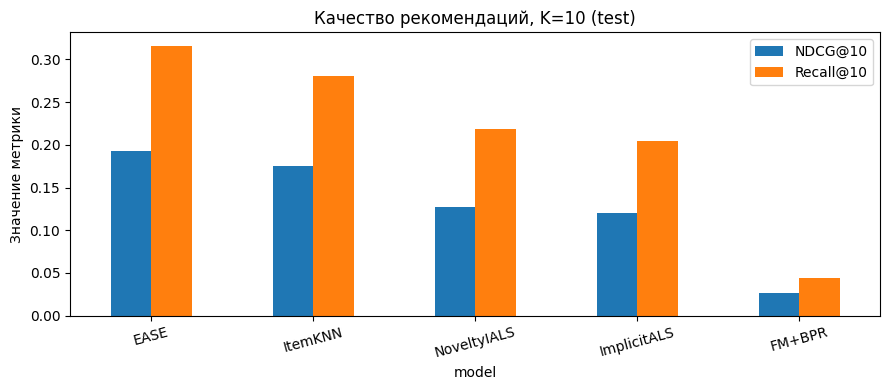

In [20]:

plot_data = test_table.set_index('model')[['NDCG@10','Recall@10']]
plot_data.plot(kind='bar', figsize=(9,4), rot=15)
plt.title('Качество рекомендаций, K=10 (test)')
plt.ylabel('Значение метрики')
plt.tight_layout()
plt.show()

In [21]:
# Пример персональных top-10 (для первого тестового пользователя).
# Числа в списке — это идентификаторы книг, а не оценки модели.
for name, examples in top10_examples.items():
    user_id, item_ids, held_out = examples[0]
    original_user, original_items = test_data.example_ids(user_id, item_ids)
    _, real_items = test_data.example_ids(user_id, held_out)
    print('\n',name, '| пользователь:',original_user)
    print('top-10:',original_items)
    print('Релевантные книги в test:',real_items[:10])


 ItemKNN | пользователь: 100634
top-10: ['103324', '67883', '169055', '94641', '121857', '36163', '53426', '269695', '89840', '103445']
Релевантные книги в test: ['51229']

 ImplicitALS | пользователь: 100634
top-10: ['103324', '89840', '169055', '376967', '36112', '78986', '67883', '51519', '391701', '121857']
Релевантные книги в test: ['51229']

 EASE | пользователь: 100634
top-10: ['103324', '67883', '121857', '169055', '94641', '36163', '184654', '103445', '51519', '383196']
Релевантные книги в test: ['51229']

 FM+BPR | пользователь: 100634
top-10: ['53426', '109636', '89840', '94641', '404509', '67883', '968', '109638', '970', '404575']
Релевантные книги в test: ['51229']

 NoveltyIALS | пользователь: 100634
top-10: ['103324', '376967', '391701', '36112', '103180', '169055', '10628', '78986', '94641', '36163']
Релевантные книги в test: ['51229']


In [22]:
winner = test_table.iloc[0]
print(f"Лучшая модель по test NDCG@10: {winner['model']}, "
      f"NDCG@10={winner['NDCG@10']:.4f}, Recall@10={winner['Recall@10']:.4f}.")
for _, row in control.iterrows():
    value = row['изменение NDCG@10']
    print(row['сравнение'], ':', f'{value:+.4f}',
          '— улучшило качество' if value>0 else ('— ухудшило качество' if value<0 else '— не изменило качество'))
print('Важно: выводы о влиянии двух модификаций относятся к validation; '
      'после подбора на validation test использован только для финального сравнения.')
print('Ограничения: отбор популярной части каталога, пропуск cold-start событий, '
      'разреженность, ограничения по вычислениям и данным о категориях.')

Лучшая модель по test NDCG@10: EASE, NDCG@10=0.1932, Recall@10=0.3160.
FM: с метапризнаками − только ID : +0.0005 — улучшило качество
Novelty-ALS − ALS (одинаковые настройки) : +0.0007 — улучшило качество
Важно: выводы о влиянии двух модификаций относятся к validation; после подбора на validation test использован только для финального сравнения.
Ограничения: отбор популярной части каталога, пропуск cold-start событий, разреженность, ограничения по вычислениям и данным о категориях.
